# Final milestone: lung crop and CNN–ViT pilot

The VPS ran pretrained feature extraction and five epochs of classifier-head optimization. This notebook executes artifact inspection and independent score recomputation locally. It does not claim to rerun training in this notebook. Full training code and logs are included in the project. M2 and this frozen-feature pilot use different protocols.


In [1]:
from pathlib import Path
import json, csv, hashlib
import numpy as np
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, roc_auc_score, confusion_matrix
ROOT=Path.cwd()
if not (ROOT/'results/summary.json').exists(): ROOT=ROOT.parent
summary=json.loads((ROOT/'results/summary.json').read_text())
assert summary['completed']
assert json.loads((ROOT/'results/verification.json').read_text())['verified']
print(json.dumps(summary['protocol'],indent=2))

{
  "experiment": "Frozen pretrained feature pilot; 5 head epochs; single CNN replaces original five-CNN proposed ablation",
  "seed": 42,
  "epochs": 5,
  "training": "Frozen ImageNet features; standardized using training only; AdamW linear head; no fresh image augmentation in this declared pilot",
  "split": "conservative person number / normal filename prefix / hash fallback",
  "checkpoint_selection": "validation macro F1; earlier epoch breaks ties",
  "test_history": "Benchmark previously inspected; not external blind holdout",
  "crop": "Fixed pretrained PSPNet at256 inference (runtime-driven departure from official512 wrapper); lung union bounding box +10% margin on original pixels before224 resize",
  "limitations": [
    "Single seed",
    "Filename patient proxies",
    "Frozen representation pilot differs from online M2 reconstruction"
  ],
  "training_records": 4164,
  "validation_records": 1042,
  "test_records": 624,
  "device": "CPU",
  "threads": 2,
  "precision": "FP32

In [2]:
rows=list(csv.DictReader((ROOT/'results/predictions.csv').open()))
y=np.array([int(r['label']) for r in rows])
for key,condition in summary['conditions'].items():
 p=np.array([float(r[key]) for r in rows]);z=(p>=.5).astype(int)
 computed={'accuracy':accuracy_score(y,z),'sensitivity':recall_score(y,z),'specificity':recall_score(1-y,1-z),'precision':precision_score(y,z,zero_division=0),'macro_f1':f1_score(y,z,average='macro'),'auc':roc_auc_score(y,p)}
 for metric,value in computed.items():assert abs(value-condition['metrics'][metric])<1e-10
 print(key,json.dumps(computed),'confusion',confusion_matrix(y,z).tolist())
print('All declared metrics independently recomputed from',len(rows),'test predictions.')

A {"accuracy": 0.8685897435897436, "sensitivity": 0.9743589743589743, "specificity": 0.6923076923076923, "precision": 0.8407079646017699, "macro_f1": 0.8503211916267859, "auc": 0.9308240192855578} confusion [[162, 72], [10, 380]]
B {"accuracy": 0.9262820512820513, "sensitivity": 0.9666666666666667, "specificity": 0.8589743589743589, "precision": 0.9195121951219513, "macro_f1": 0.9199107142857144, "auc": 0.9703265395573087} confusion [[201, 33], [13, 377]]
C {"accuracy": 0.8814102564102564, "sensitivity": 0.9794871794871794, "specificity": 0.717948717948718, "precision": 0.8526785714285714, "macro_f1": 0.865603352930904, "auc": 0.9472496164803857} confusion [[168, 66], [8, 382]]
D {"accuracy": 0.9375, "sensitivity": 0.982051282051282, "specificity": 0.8632478632478633, "precision": 0.9228915662650602, "macro_f1": 0.931758338824783, "auc": 0.9757396449704141} confusion [[202, 32], [7, 383]]
All declared metrics independently recomputed from 624 test predictions.


In [3]:
for path in sorted((ROOT/'results').glob('*_history.json')):
 history=json.loads(path.read_text())
 assert len(history)==5
 print(path.name,'epochs',len(history),'validation macro F1',[round(e['validation']['macro_f1'],4) for e in history])
print('Crop audit:',summary.get('crop_audit'))
print('Paired crop effect interval:',summary.get('paired_macro_f1_B_minus_A_95CI'))

deit_tiny_crop_history.json epochs 5 validation macro F1 [0.8352, 0.8643, 0.8651, 0.8763, 0.8883]
deit_tiny_full_history.json epochs 5 validation macro F1 [0.8815, 0.9057, 0.9152, 0.9207, 0.9325]
resnet18_crop_history.json epochs 5 validation macro F1 [0.8438, 0.8845, 0.8975, 0.901, 0.9072]
resnet18_full_history.json epochs 5 validation macro F1 [0.9067, 0.9355, 0.9434, 0.9468, 0.9549]
Crop audit: {'unique_images': 5824, 'fallbacks': 82}
Paired crop effect interval: [0.040375225499737696, 0.10161032520812266]


In [4]:
for p in sorted((ROOT/'results').glob('*.pt')):
 print(p.name,hashlib.sha256(p.read_bytes()).hexdigest())
print('The training source is run_experiment.py; use the recorded VPS environment and split for reproduction.')

deit_tiny_crop.pt a4758c80a3f178b0230c6289cf08ea00604d3a09033b50973c235834e9760184
deit_tiny_full.pt b7cddd1ba8e50ba501a3cb1279c460cc32be37639c67880b42930c5c02cabc70
resnet18_crop.pt 843dfea2da87c517836d0d381e59c0d6336e5fc2f79f70803dad0fe7de81ed3e
resnet18_full.pt a2a8a02f4d7c6607a88d06b038d7e77c1e0a12c143545b30a277085698b7f20f
The training source is run_experiment.py; use the recorded VPS environment and split for reproduction.


## Training and validation histories

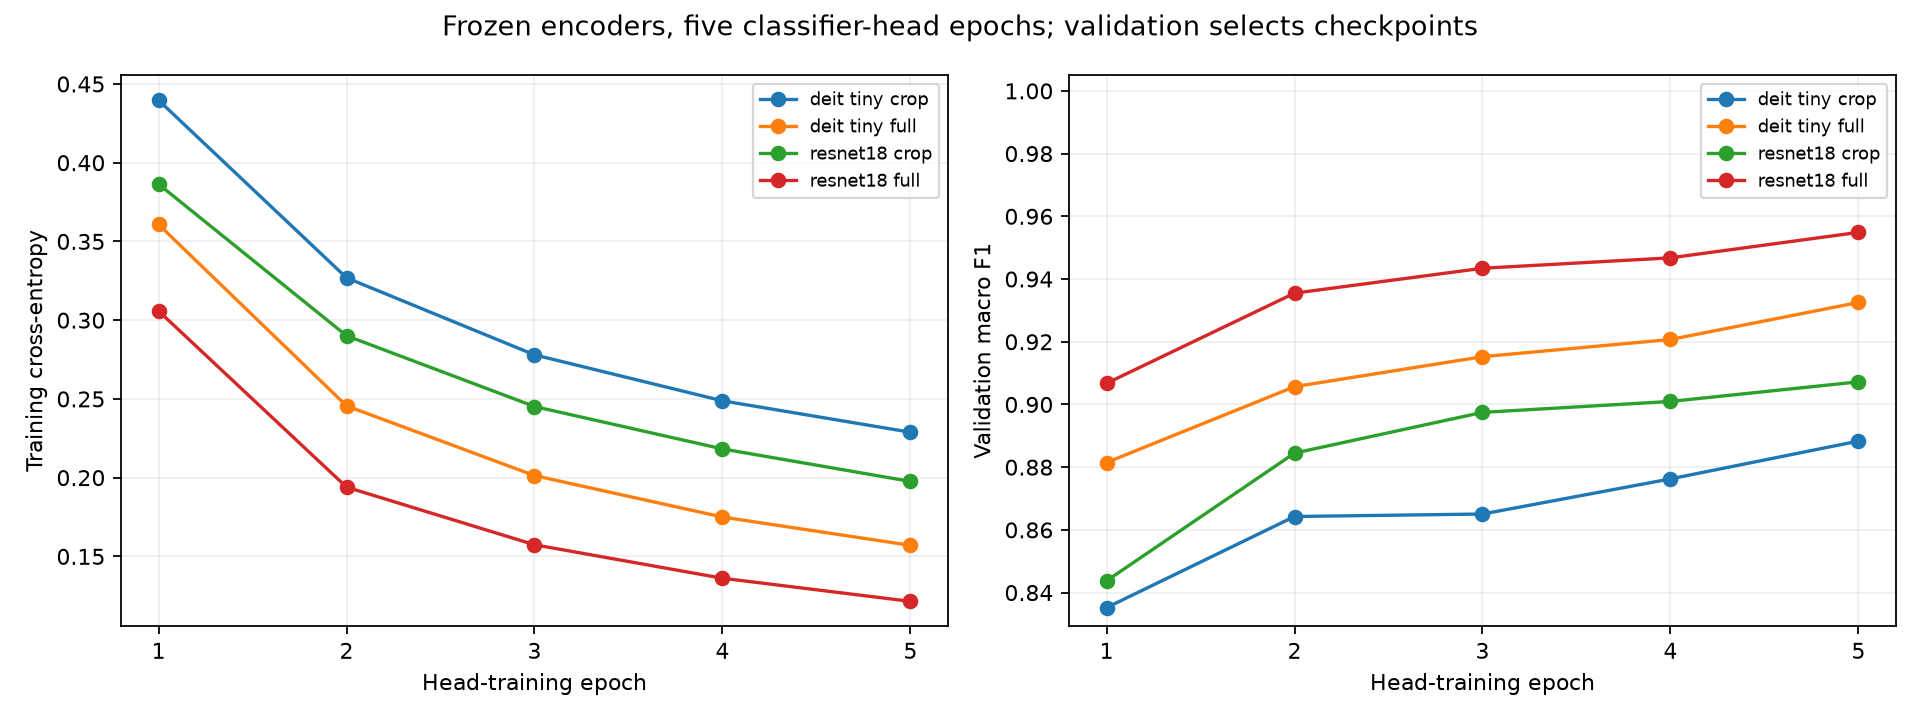

## ROC curves

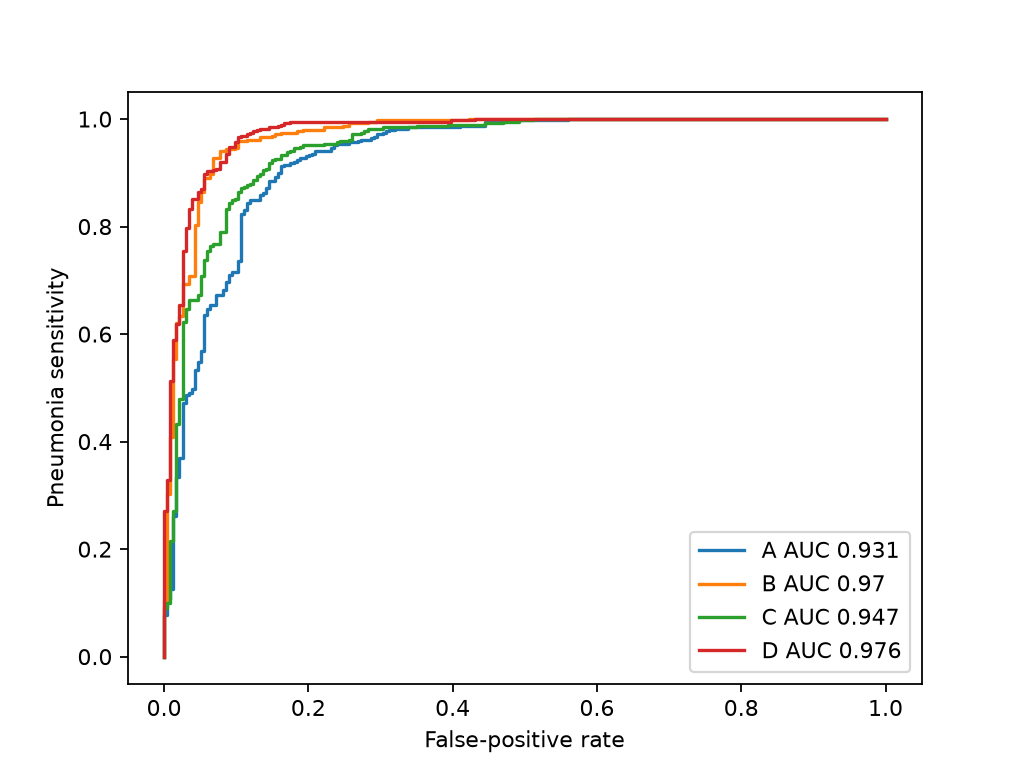

## Confusion matrices

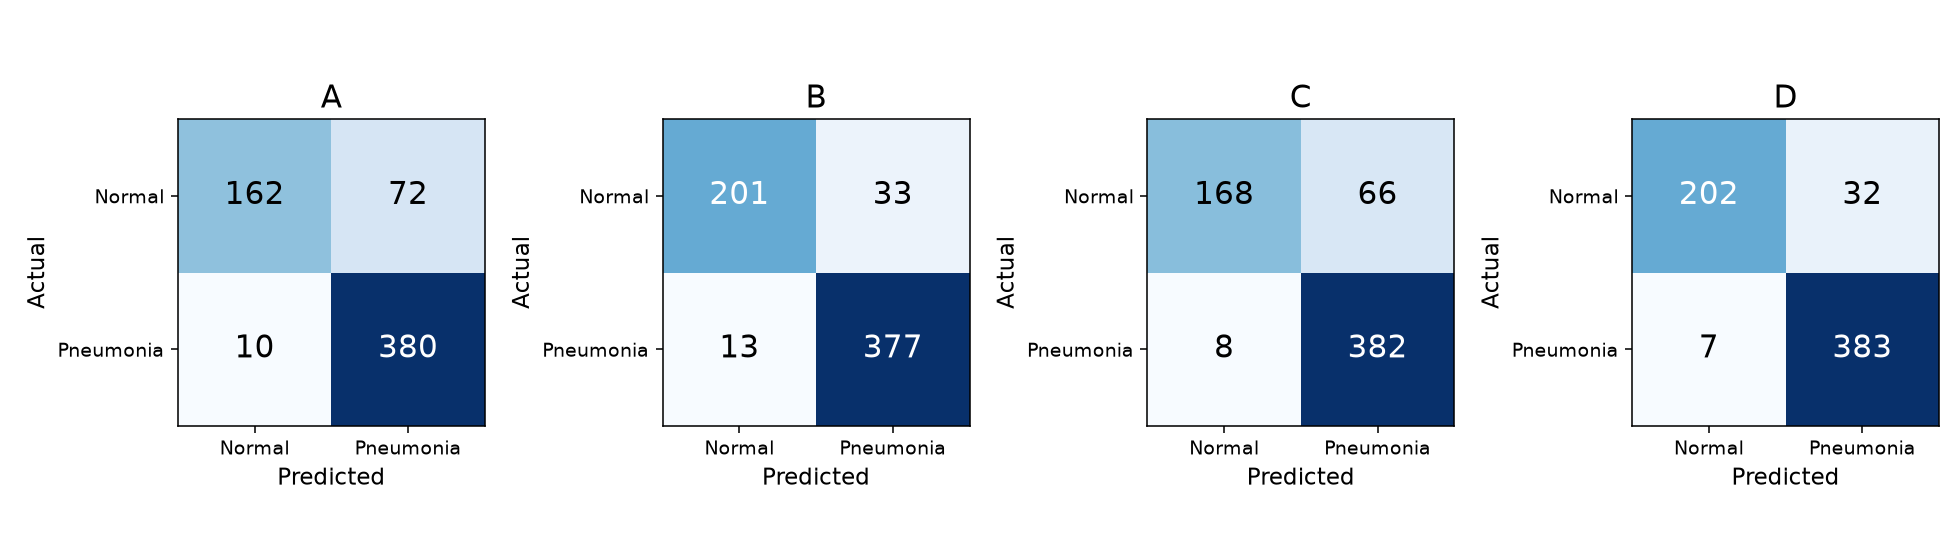

## Actual training-image preprocessing

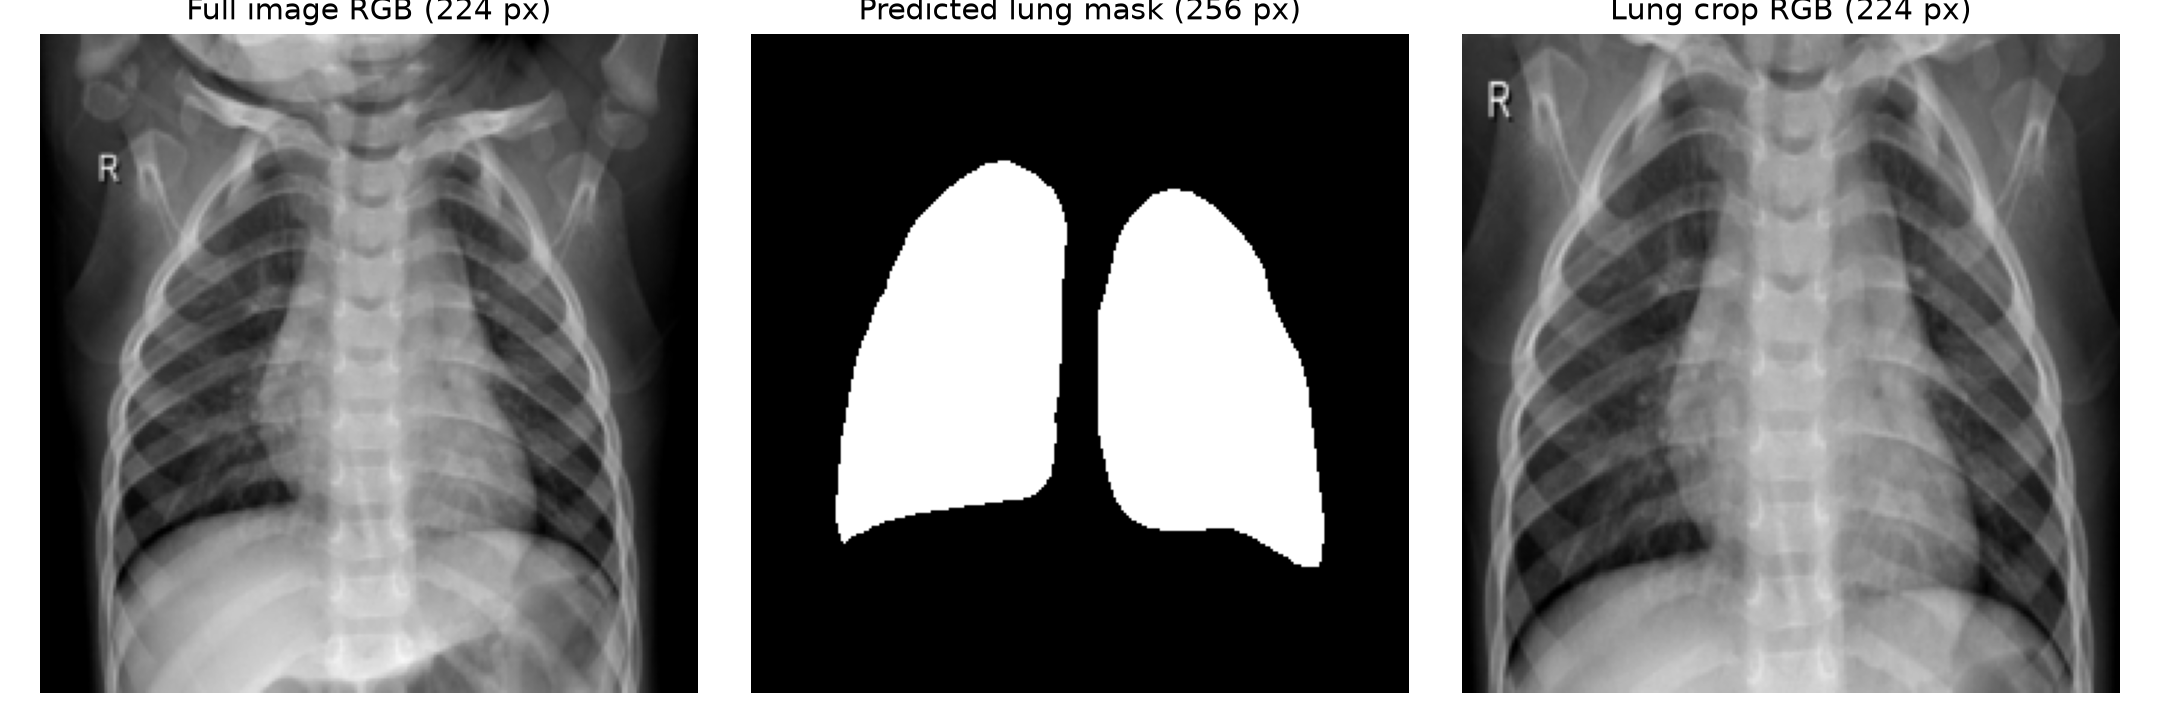

## Actual crop-hybrid errors

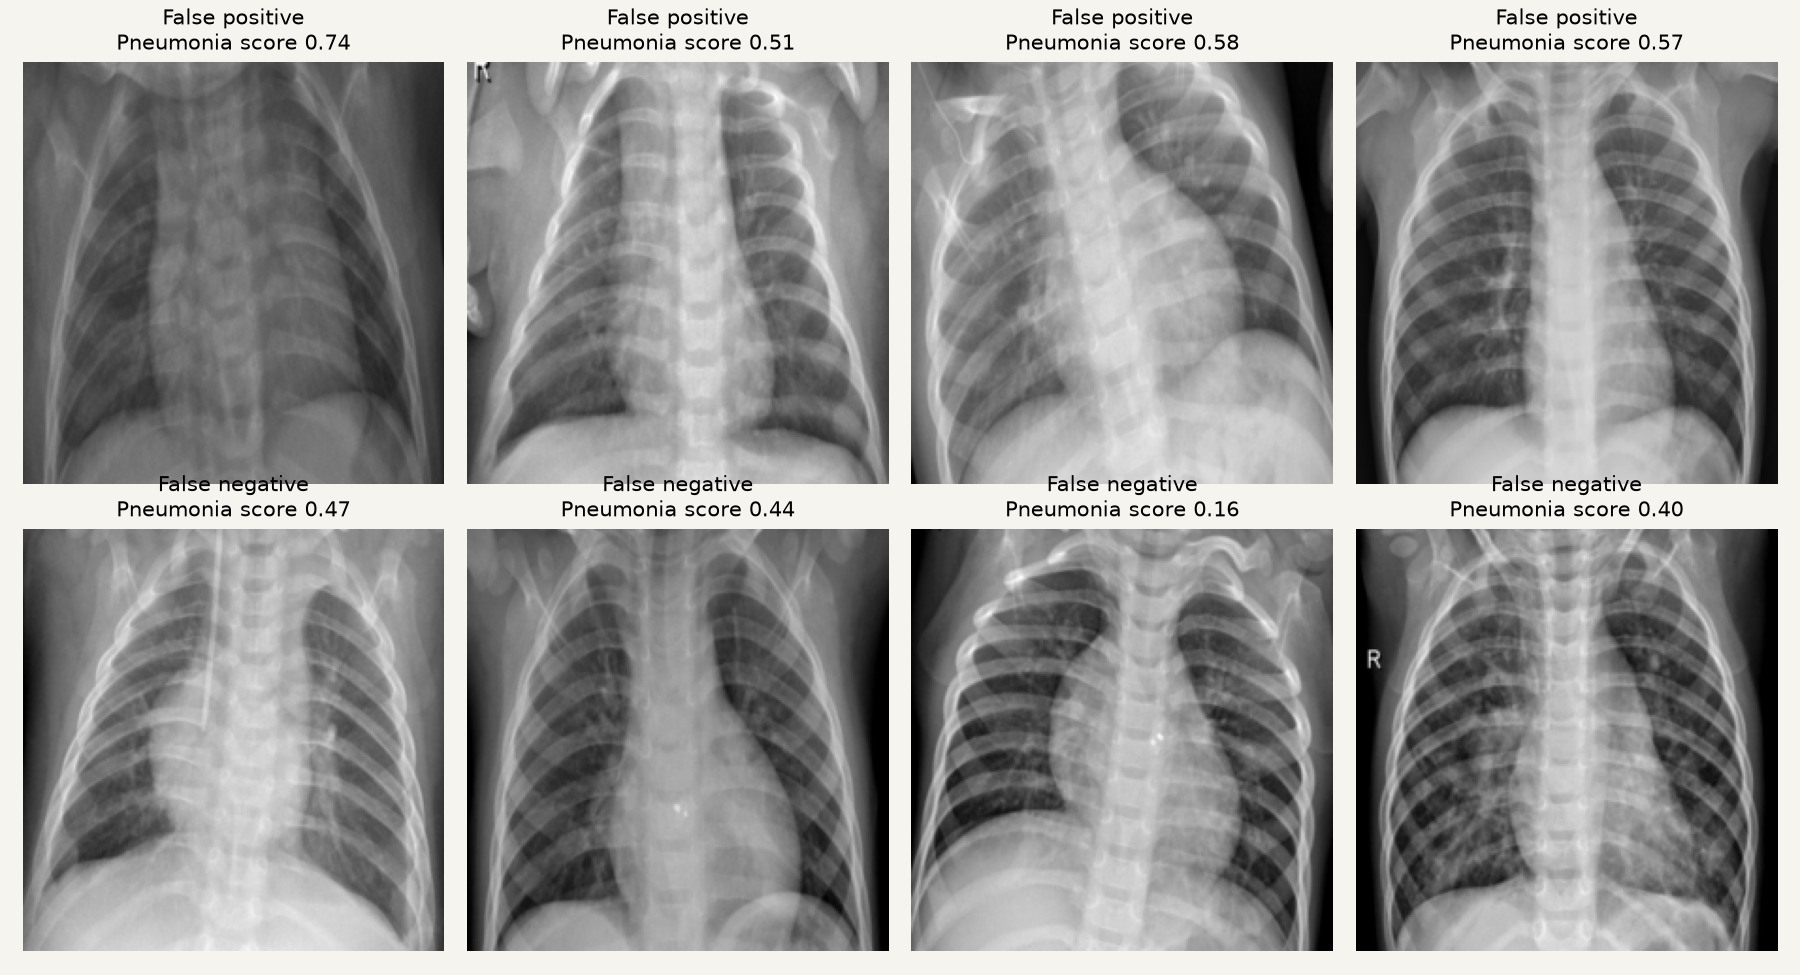

## Training implementation (documented source)

```python
"""Bounded, declared M4 frozen-feature pilot. No test-based selection."""
import os
os.environ.update(OMP_NUM_THREADS='2',OPENBLAS_NUM_THREADS='2',TORCH_HOME=str(__import__('pathlib').Path(__file__).resolve().parents[1]/'torch_cache'))
import io,json,time,gc,hashlib,subprocess,random,csv,re
from pathlib import Path
import numpy as np,torch
from PIL import Image
from torchvision import models,transforms
from sklearn.metrics import accuracy_score,recall_score,precision_score,f1_score,roc_auc_score,confusion_matrix,roc_curve
P=Path(__file__).resolve().parent;ROOT=P.parent;DATA=P/'data';OUT=P/'results'
DATA.mkdir(exist_ok=True);OUT.mkdir(exist_ok=True);torch.set_num_threads(2)
def save(p,d):
 t=p.with_suffix('.tmp');t.write_text(json.dumps(d,indent=2));t.replace(p)
def status(phase,**kw):save(P/'status.json',dict(phase=phase,time=time.time(),**kw));print(phase,kw,flush=True)
def guard(reserve=512*1024**2):
 c=Path('/sys/fs/cgroup');limit=int((c/'memory.max').read_text());current=int((c/'memory.current').read_text());stat=dict(line.split() for line in (c/'memory.stat').read_text().splitlines());clean_file=max(0,int(stat.get('file',0))-int(stat.get('shmem',0))-int(stat.get('file_dirty',0))-int(stat.get('file_writeback',0)));available=limit-current+clean_file
 if available<reserve:raise RuntimeError(f'Insufficient reclaimable cgroup memory: {available/1024**2:.0f}MiB')
 if __import__('shutil').disk_usage(P).free<400*1024**2:raise RuntimeError('Disk reserve reached')
def metrics(y,p):
 z=p>=.5
 return dict(accuracy=accuracy_score(y,z),sensitivity=recall_score(y,z),specificity=recall_score(1-y,1-z),precision=precision_score(y,z,zero_division=0),macro_f1=f1_score(y,z,average='macro'),normal_f1=f1_score(y,z,pos_label=0),pneumonia_f1=f1_score(y,z,pos_label=1),auc=roc_auc_score(y,p),confusion_matrix=confusion_matrix(y,z).tolist())
split=json.loads((ROOT/'m2_m3/experiments/restart15/split.json').read_text());records=split['records']+split['test_records'];n=len(split['records']);tr=np.array(split['train_indices']);va=np.array(split['validation_indices']);te=np.arange(n,len(records));y=np.array([r['label'] for r in records]);assert not set(tr)&set(va)
# Raw-hash duplicates and conservative filename proxies follow the saved audited split.
for kind in ['full','crop','masks']:(DATA/kind).mkdir(exist_ok=True)
def prepare():
 cache=DATA/'crop_metadata.json'
 if cache.exists():
  existing=json.loads(cache.read_text())
  if all(r['sha256'] in existing and all((DATA/kind/(r['sha256']+'.png')).exists() for kind in ['full','crop','masks']) for r in records):
   status('segmentation_cache_complete',unique_images=len(existing));return
 import torchxrayvision as xrv,pyarrow.parquet as pq
 from scipy.ndimage import label
 guard(450*1024**2);seg=xrv.baseline_models.chestx_det.PSPNet();seg.eval();idx=[seg.targets.index('Left Lung'),seg.targets.index('Right Lung')]
 lookup={r['sha256']:r for r in records}; meta={}
 cache=DATA/'crop_metadata.json'
 if cache.exists():meta=json.loads(cache.read_text())
 api='https://huggingface.co/api/datasets/hf-vision/chest-xray-pneumonia/tree/main/data'
 files=json.loads(subprocess.check_output(['curl','-fLsS','--retry','2',api]))
 for f in files:
  if not f['path'].endswith('.parquet'):continue
  prior_manifest=ROOT/'m2_m3/data'/Path(f['path']).with_suffix('.manifest.json').name
  if prior_manifest.exists():
   needed=[r['sha256'] for r in json.loads(prior_manifest.read_text()) if r['sha256'] in lookup]
   if needed and all(sha in meta for sha in needed):
    status('skip_completed_shard',shard=f['path']);continue
  shard=DATA/'source.parquet';status('download_source',shard=f['path'])
  if not shard.exists() or hashlib.sha256(shard.read_bytes()).hexdigest()!=f['lfs']['oid']:subprocess.run(['curl','-fLsS','--retry','3','--max-time','900','https://huggingface.co/datasets/hf-vision/chest-xray-pneumonia/resolve/main/'+f['path'],'-o',str(shard)],check=True)
  assert hashlib.sha256(shard.read_bytes()).hexdigest()==f['lfs']['oid']
  for batch in pq.ParquetFile(shard).iter_batches(batch_size=1):
   for row in batch.to_pylist():
    raw=row['image']['bytes'];sha=hashlib.sha256(raw).hexdigest()
    if sha not in lookup or sha in meta:continue
    im=Image.open(io.BytesIO(raw)).convert('RGB');w,h=im.size
    original224=im.resize((224,224),Image.Resampling.BILINEAR)
    cached=ROOT/'m2_m3'/lookup[sha]['path']
    if cached.exists():
     with Image.open(cached) as old:assert np.array_equal(np.asarray(original224),np.asarray(old.convert('RGB'))),'Full-image source/cache mismatch'
    gray=im.convert('L')
    # Match official xrv normalization; preserve aspect coordinates by resizing entire image.
    arr=np.asarray(gray.resize((256,256),Image.Resampling.BILINEAR),dtype=np.float32)
    x=torch.from_numpy(xrv.datasets.normalize(arr,255)).unsqueeze(0).unsqueeze(0)
    guard();tick=time.time()
    with torch.inference_mode():mask=(seg.model(seg.transform((x.repeat(1,3,1,1)+1024)/2048)).sigmoid()[0,idx].max(0).values>.5).numpy()
    ys,xs=np.where(mask);fraction=float(mask.mean());fallback=len(xs)==0 or fraction<.08 or fraction>.85
    if fallback:box=(0,0,w,h)
    else:
     x0,x1=xs.min()/256*w,(xs.max()+1)/256*w;y0,y1=ys.min()/256*h,(ys.max()+1)/256*h
     dx=(x1-x0)*.1;dy=(y1-y0)*.1;box=(max(0,int(x0-dx)),max(0,int(y0-dy)),min(w,int(x1+dx)),min(h,int(y1+dy)))
    im.convert('RGB').resize((224,224),Image.Resampling.BILINEAR).save(DATA/'full'/f'{sha}.png')
    im.crop(box).convert('RGB').resize((224,224),Image.Resampling.BILINEAR).save(DATA/'crop'/f'{sha}.png')
    Image.fromarray(mask.astype('uint8')*255).save(DATA/'masks'/f'{sha}.png')
    meta[sha]=dict(bbox=list(box),original_size=[w,h],fallback=bool(fallback),mask_fraction=fraction)
    if len(meta)%25==0:save(cache,meta);status('segmentation',complete=len(meta),total=len(lookup),last_image_seconds=time.time()-tick)
  save(cache,meta);shard.unlink()
 del seg;gc.collect();save(cache,meta)

def features(kind,arch):
 target=DATA/f'{arch}_{kind}.npy'
 if target.exists():return np.load(target)
 torch.manual_seed(42)
 if arch=='resnet18':m=models.resnet18(weights=models.ResNet18_Weights.DEFAULT);m.fc=torch.nn.Identity()
 else:
  import timm
  m=timm.create_model('deit_tiny_patch16_224',pretrained=True,num_classes=0)
 m.eval();ts=transforms.Compose([transforms.Resize((224,224)),transforms.ToTensor(),transforms.Normalize([.485,.456,.406],[.229,.224,.225])]);rows=[];started=time.time()
 for i,r in enumerate(records):
  source=DATA/kind/(r['sha256']+'.png')
  if not source.exists() and kind=='full':source=ROOT/'m2_m3'/r['path']
  guard()
  with Image.open(source) as im:x=ts(im.convert('RGB')).unsqueeze(0)
  with torch.inference_mode():rows.append(m(x)[0].numpy().copy())
  if i%100==0:status('features',kind=kind,arch=arch,complete=i,total=len(records),elapsed=time.time()-started)
 z=np.array(rows);np.save(target,z);del m;gc.collect();return z

def fit(z,name):
 torch.manual_seed(42);np.random.seed(42);random.seed(42)
 mean=z[tr].mean(0);std=z[tr].std(0).clip(.001);x=torch.tensor((z-mean)/std,dtype=torch.float32);labels=torch.tensor(y);m=torch.nn.Linear(z.shape[1],2);opt=torch.optim.AdamW(m.parameters(),lr=.001,weight_decay=.01);history=[];best=-1;best_state=None
 for epoch in range(5):
  m.train();order=tr[np.random.permutation(len(tr))];losses=[]
  for start in range(0,len(order),32):
   ix=order[start:start+32];opt.zero_grad();loss=torch.nn.functional.cross_entropy(m(x[ix]),labels[ix]);loss.backward();opt.step();losses.append(float(loss.detach()))
  m.eval()
  with torch.inference_mode():p=m(x[va]).softmax(-1)[:,1].numpy()
  met=metrics(y[va],p);history.append(dict(epoch=epoch+1,loss=float(np.mean(losses)),validation=met));score=met['macro_f1']
  if score>best:best=score;best_state={k:v.clone() for k,v in m.state_dict().items()};selected=epoch+1
 m.load_state_dict(best_state)
 with torch.inference_mode():p=m(x).softmax(-1)[:,1].numpy()
 torch.save(dict(state_dict=best_state,mean=mean,std=std,architecture=name,selected_epoch=selected),OUT/(name+'.pt'));save(OUT/(name+'_history.json'),history)
 return p

def main():
 protocol=dict(experiment='Frozen pretrained feature pilot; 5 head epochs; single CNN replaces original five-CNN proposed ablation',seed=42,epochs=5,training='Frozen ImageNet features; standardized using training only; AdamW linear head; no fresh image augmentation in this declared pilot',split=split['group_definition'],checkpoint_selection='validation macro F1; earlier epoch breaks ties',test_history='Benchmark previously inspected; not external blind holdout',crop='Fixed pretrained PSPNet at256 inference (runtime-driven departure from official512 wrapper); lung union bounding box +10% margin on original pixels before224 resize',limitations=['Single seed','Filename patient proxies','Frozen representation pilot differs from online M2 reconstruction'])
 result=dict(completed=False,protocol=protocol,conditions={});preds={}
 def record(key,p):
  preds[key]=p;result['conditions'][key]=dict(metrics=metrics(y[te],p[te]));save(OUT/'partial_summary.json',result)
 status('full_image_control');a=fit(features('full','resnet18'),'resnet18_full');record('A',a)
 status('original_resolution_segmentation');prepare()
 b=fit(features('crop','resnet18'),'resnet18_crop');record('B',b)
 for kind,key,cnn in [('full','C',a),('crop','D',b)]:
  v=fit(features(kind,'deit_tiny'),f'deit_tiny_{kind}');best=(-1,None,None)
  for weight in [0,.25,.5,.75,1]:
   blend=(1-weight)*cnn+weight*v;s=metrics(y[va],blend[va])['macro_f1']
   if s>best[0]:best=(s,weight,blend)
  record(key,best[2]);result['conditions'][key]['vit_weight']=best[1]
 meta=json.loads((DATA/'crop_metadata.json').read_text());result['crop_audit']=dict(unique_images=len(meta),fallbacks=sum(r['fallback'] for r in meta.values()))
 rng=np.random.default_rng(123);diffs=[]
 groups={}
 for i in te:
  name=records[i].get('source_path') or records[i]['sha256'];person=re.search(r'person(\d+)',name);key=('person'+person[1]) if person else name.split('-0001')[0];groups.setdefault(key,[]).append(i)
 groupids=list(groups)
 for _ in range(1000):
  ix=np.concatenate([groups[groupids[j]] for j in rng.integers(0,len(groupids),len(groupids))]);diffs.append(metrics(y[ix],b[ix])['macro_f1']-metrics(y[ix],a[ix])['macro_f1'])
 result['paired_macro_f1_B_minus_A_95CI']=np.quantile(diffs,[.025,.975]).tolist();save(OUT/'partial_summary.json',result)
 with (OUT/'predictions.csv').open('w') as f:
  w=csv.writer(f);w.writerow(['sha256','label']+list(preds))
  for i in te:w.writerow([records[i]['sha256'],int(y[i])]+[float(preds[k][i]) for k in preds])
 import matplotlib;matplotlib.use('Agg');import matplotlib.pyplot as plt
 fig,ax=plt.subplots()
 for k,p in preds.items():fpr,tpr,_=roc_curve(y[te],p[te]);ax.plot(fpr,tpr,label=k+' AUC '+str(round(result['conditions'][k]['metrics']['auc'],3)))
 ax.set(xlabel='False-positive rate',ylabel='Pneumonia sensitivity');ax.legend();fig.savefig(OUT/'roc.png',dpi=160);plt.close(fig)
 result['completed']=True;result['bootstrap_unit']='conservative filename patient proxy';save(OUT/'summary.json',result)
 status('complete',conditions=list(preds))
if __name__=='__main__':main()

```